> **Language & Quick Links**: [🇰🇷 Korean (`notebooks/ko/stage0_overview_walkthrough_ko.ipynb`)](../ko/stage0_overview_walkthrough_ko.ipynb) · **🇺🇸 English (Current Folder: `notebooks/en/`)** ｜ [Methodology Guide](../../methodology/en/METHODOLOGY_EN.md) ｜ [Notebook Index (README)](../README.md) ｜ [Open Live Studio Tab](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=overview)
>
> **Lifecycle Navigation**: **[▶ 0. End-to-End Overview](./stage0_overview_walkthrough_en.ipynb)** → [Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) → [Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) → [Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) → [Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb) → [Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb)

---

# 0. End-to-End Entrypoint — 8-Phase Engineering Pipeline & 5-Stage Agentic Ontology Walkthrough
## Prepare → Analyze → Parse → Integrate → Build Graph → Build Agent → Answer (GQL) → Verify & Gate

This master entrypoint notebook walks through the complete **Agentic Ontology Starter Pack v2.0** methodology end to end. Rather than isolated data exploration, it connects **1. Preparation → 2. Analysis & CQ Design → 3. Markdown Parsing & SHA-256 Anchoring → 4. 3-Layer Wiki & Semantic Rule Integration → 5. Physical Property Graph Construction → 6. 8-Tool MCP & 2-Pass Agent Setup → 7. Parameterized ISO GQL & Grounded Answering → 8. End-to-End Lineage & 50-Trial Benchmark Verification**, showing intermediate tables, bound GQL variables, data outputs, and graph design schematics at every phase.

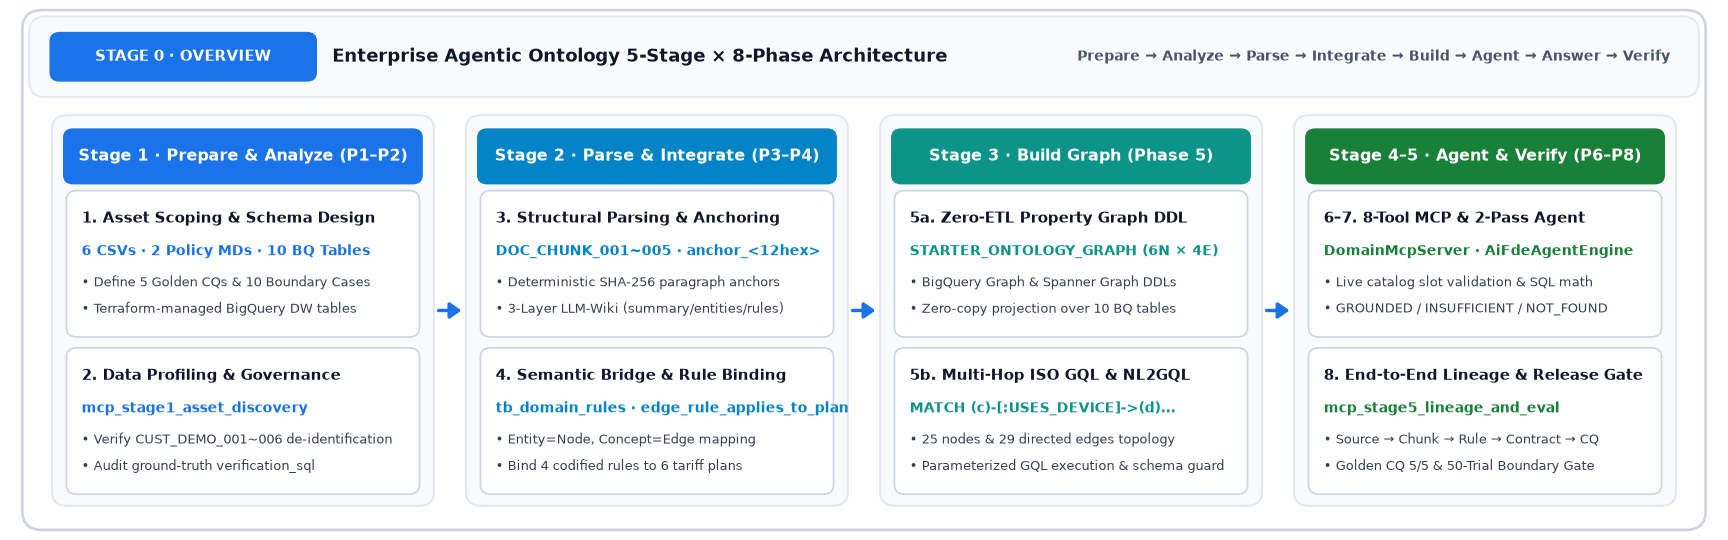

### 8-Phase Engineering Flow & Bilingual Notebook Navigation Map (`notebooks/ko/` · `notebooks/en/`)

| Engineering Phase | Canonical Stage | Core Modules & MCP Tools | Intermediate Data, Tables & Graph Schematics | Korean Notebook (`ko/`) | English Notebook (`en/`) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **1. Prepare**<br>**2. Analyze** | **Stage 1**<br>(`Step 1.1`–`1.2`) | `terraform/bigquery.tf`<br>`mcp_stage1_asset_discovery`<br>`H.check_cq_sql()` | Raw CSV/MD inventory, 10-table ER blueprint, de-identified contracts, subsidy heatmap, 5 Golden CQs SQL check | [`stage1_ko`](../ko/stage1_asset_and_cq_ko.ipynb) | [`stage1_en`](./stage1_asset_and_cq_en.ipynb) |
| **3. Parse**<br>**4. Integrate** | **Stage 2**<br>(`Step 2.1`–`2.2`) | `pipeline/ingest.py`<br>`mcp_stage2_wiki_and_semantic`<br>`H.propose_triples()` | `DOC_CHUNK` regex parsing & SHA-256 anchor table, 3-Layer Wiki, Gemini triple extraction, Semantic Graph schematic | [`stage2_ko`](../ko/stage2_wiki_and_semantic_graph_ko.ipynb) | [`stage2_en`](./stage2_wiki_and_semantic_graph_en.ipynb) |
| **5. Build Graph** | **Stage 3**<br>(`Step 3.1`–`3.2`) | `pipeline/graph_builder.py`<br>`mcp_stage3_property_graph`<br>`H.run_gql()` / `H.nl2gql()` | 6 Node × 4 Edge metamodel schematic, BQ/Spanner DDL, full topology & 1..2-hop ego graph, parameterized ISO GQL | [`stage3_ko`](../ko/stage3_property_graph_bigquery_spanner_ko.ipynb) | [`stage3_en`](./stage3_property_graph_bigquery_spanner_en.ipynb) |
| **6. Build Agent**<br>**7. Answer** | **Stage 4**<br>(`Step 4.1`–`4.2`) | `src/agent/mcp_server.py`<br>`src/agent/reasoning_engine.py`<br>`mcp_stage4_agent_orchestration` | 2-Pass agent orchestration schematic, 8-tool MCP catalog, slot parsing, 180d penalty curve, Golden CQ & boundary answers | [`stage4_ko`](../ko/stage4_agent_and_mcp_execution_ko.ipynb) | [`stage4_en`](./stage4_agent_and_mcp_execution_en.ipynb) |
| **8. Verify & Gate** | **Stage 5**<br>(`Step 5.1`–`5.2`) | `pipeline/validator.py`<br>`mcp_stage5_lineage_and_eval`<br>`H.recheck_cq()` | end-to-end lineage table & multipartite graph, live CQ re-audit, Boundary 50-trial metrics & Gate 1..5 checklist | [`stage5_ko`](../ko/stage5_lineage_and_evaluation_ko.ipynb) | [`stage5_en`](./stage5_lineage_and_evaluation_en.ipynb) |

### 3-Track Selective Adoption Model (`config/starter_config.json`)

| Track | Active Stages | Graph Engine | Target Scenario |
| :--- | :--- | :--- | :--- |
| **Track 1 · Lite** | `Stage 1 → Stage 2 → Stage 4` | `none` | Source documents only, no customer tables. Source chunks build the document-based Wiki; the agent receives all `tb_doc_chunks` rows as context and answers with chunk ID citations; citation CQs are scored |
| **Track 2 · Standard** | `Stage 1 → Stage 2 → Stage 3 → Stage 4` | `bigquery` / `spanner` | Unifying 4 structured DW ledgers and unstructured rules into a Zero-ETL Property Graph for multi-hop ISO GQL |
| **Track 3 · Full-Stack** | `Stage 1 → Stage 2 → Stage 3 → Stage 4 → Stage 5` | `bigquery` | Full lifecycle operation including end-to-end lineage, 5 Golden CQs, 50-trial boundary benchmark, and Cloud Run release gates |


In [1]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("en")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. [Architecture Blueprint] 8-Phase Engineering Pipeline & 10-Table Schema Blueprint


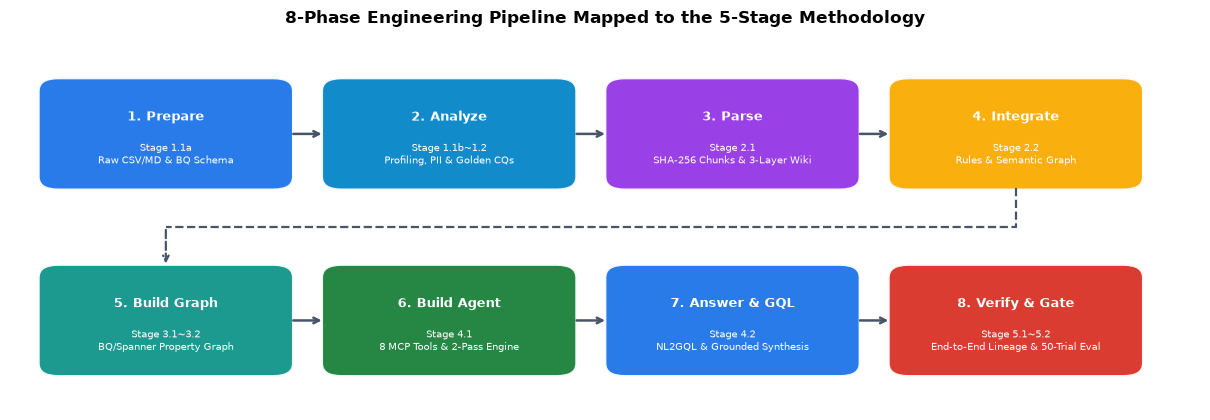

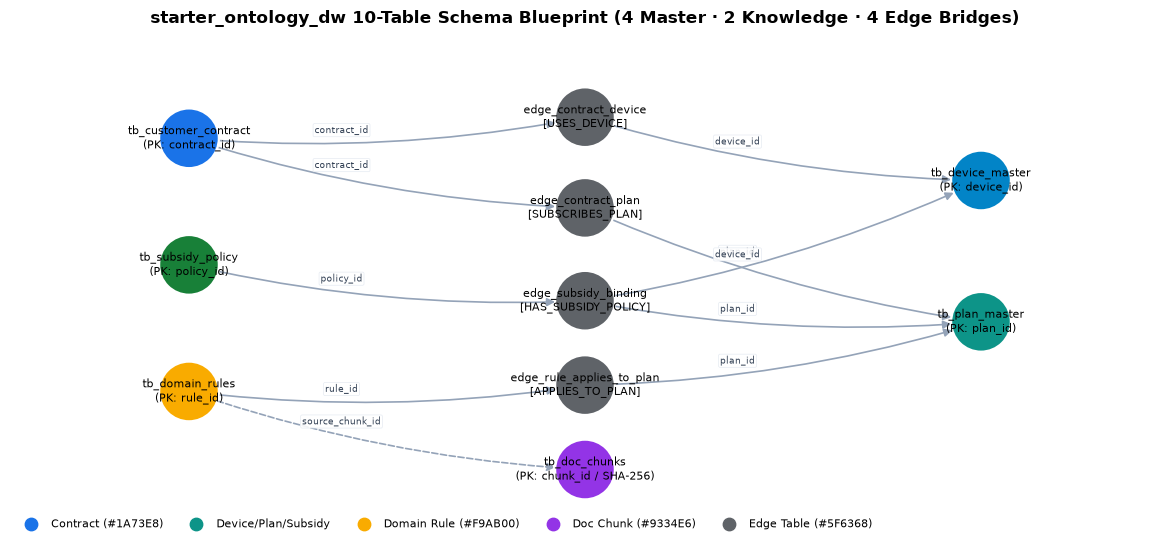

In [2]:
H.draw_eight_phase_flow()
H.draw_table_er_blueprint()


### 2. [Phase 1–2 · Stage 1: Prepare & Analyze] Raw Input Inventory & BigQuery 10-Table Profiling (`mcp_stage1_asset_discovery` + `%%bqsql`)


In [3]:
H.show(H.raw_inputs_inventory())
res_s1 = server.execute_tool("mcp_stage1_asset_discovery")
H.show_tool(res_s1)


,input_file,asset_type,volume,key_contents
0,01_guides/sample_policy_guide.md,Unstructured Policy Guide,"16 lines (1,363 chars)","DOC_CHUNK_001~003 (Subsidy Cap, 180d Retention, Prorated Formula)"
1,01_guides/sample_welfare_exemption_guide.md,Unstructured Policy Guide,"11 lines (1,252 chars)","DOC_CHUNK_004~005 (Senior/Welfare Exemption, 24M TCO Rule)"
2,03_tables/devices.csv,Master CSV (Structured),4 rows,"device_id, pet_name, storage, manufacturer, factory_price, release_date"
3,03_tables/plans.csv,Master CSV (Structured),6 rows,"plan_id, plan_name, tier_category, monthly_fee, min_maintenance_days, selective_discou..."
4,03_tables/subsidies.csv,Master CSV (Structured),5 rows,"policy_id, device_id, plan_id, basic_subsidy, distribution_subsidy, mandatory_retentio..."
5,03_tables/customer_contracts.csv,Master CSV (Structured),6 rows,"contract_id, customer_id (CUST_DEMO_*), device_id, plan_id, contract_type, elapsed_day..."
6,03_tables/domain_rules.csv,Semantic Rule CSV,4 rows,"rule_id, rule_name, rule_category, condition_expr, formula_expr, source_chunk_id"
7,03_tables/rule_plan_edges.csv,Semantic Bridge CSV,12 rows,"edge_id, rule_id, plan_id, source_chunk_id, relation_label_ko"
8,04_cq/golden_competency_questions.json,Golden CQ Benchmark Spec,5 items,"5 Golden CQs with expected_math, verification_sql, grounded_chunk"
9,04_cq/boundary_cases.json,Boundary Benchmark Spec,10 items,"10 Boundary Cases with root_cause_code, accept_answer_status"


**`mcp_stage1_asset_discovery`** · engine `bigquery` · status `SUCCESS` · steps `profile_tables, scan_guides, prune_noise, tag_pii_governance` · jobs 2 (1,545.1 ms)

BigQuery `seanjung-poc.starter_ontology_dw`: 10 tables (59 rows measured) · 0 PII de-identification rule violations

- `job_4qVJz8hLIlvtC_0Bz4sc9693Lv60`
- `job_Xym0cR6pvnE8omh7VNGhJTb_BIcU`

In [4]:
%%bqsql df_tables
SELECT table_id, row_count, size_bytes,
  CASE WHEN STARTS_WITH(table_id, 'edge_') THEN '3_edge_bridge'
       WHEN table_id IN ('tb_doc_chunks', 'tb_domain_rules') THEN '2_knowledge_wiki'
       ELSE '1_structured_master' END AS table_role
FROM `seanjung-poc.starter_ontology_dw.__TABLES__`
ORDER BY table_role, table_id


,table_id,row_count,size_bytes,table_role
0,tb_customer_contract,6,1096,1_structured_master
1,tb_device_master,4,452,1_structured_master
2,tb_plan_master,6,663,1_structured_master
3,tb_subsidy_policy,5,582,1_structured_master
4,tb_doc_chunks,5,2779,2_knowledge_wiki
5,tb_domain_rules,4,2018,2_knowledge_wiki
6,edge_contract_device,6,368,3_edge_bridge
7,edge_contract_plan,6,379,3_edge_bridge
8,edge_rule_applies_to_plan,12,1930,3_edge_bridge
9,edge_subsidy_binding,5,342,3_edge_bridge


,table_id,row_count,size_bytes,table_role
0,tb_customer_contract,6,1096,1_structured_master
1,tb_device_master,4,452,1_structured_master
2,tb_plan_master,6,663,1_structured_master
3,tb_subsidy_policy,5,582,1_structured_master
4,tb_doc_chunks,5,2779,2_knowledge_wiki
5,tb_domain_rules,4,2018,2_knowledge_wiki
6,edge_contract_device,6,368,3_edge_bridge
7,edge_contract_plan,6,379,3_edge_bridge
8,edge_rule_applies_to_plan,12,1930,3_edge_bridge
9,edge_subsidy_binding,5,342,3_edge_bridge


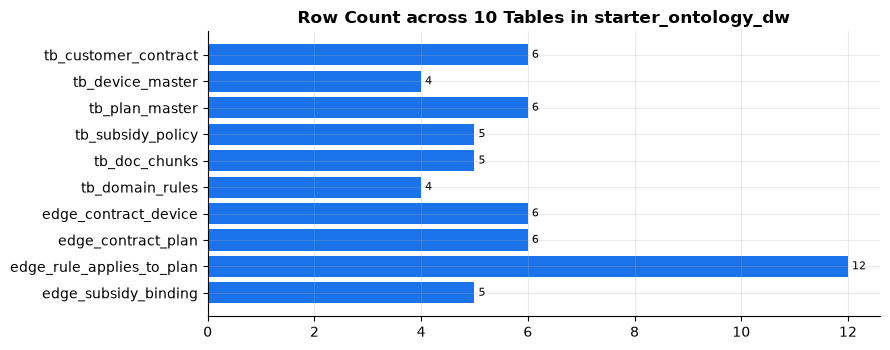

In [5]:
H.show(df_tables)
H.bar(df_tables, "table_id", "row_count", "Row Count across 10 Tables in starter_ontology_dw", horizontal=True)


### 3. [Phase 3–4 · Stage 2: Parse & Integrate] SHA-256 Guide Chunking, 3-Layer Wiki Compilation & Semantic Ontology Schematic


,chunk_id,source_file,section_title,chars,computed_anchor,bq_stored_anchor,sha256_match,excerpt
0,DOC_CHUNK_001,sample_policy_guide.md,Overview & Scope,222,anchor_a52e1a72869f,anchor_a52e1a72869f,True,## 1. General Principles
1,DOC_CHUNK_002,sample_policy_guide.md,Baseline Plan Commitment (Six-Plan Rule),467,anchor_3003b683cea0,anchor_3003b683cea0,True,## 2. 180-Day Baseline Plan Commitment Rule
2,DOC_CHUNK_003,sample_policy_guide.md,Penalty Math Formula,444,anchor_47971ec8e4d8,anchor_47971ec8e4d8,True,## 3. Penalty Settlement Computation Formula
3,DOC_CHUNK_004,sample_welfare_exemption_guide.md,Statutory Penalty Exemptions,583,anchor_269d9c42e05c,anchor_269d9c42e05c,True,## 4. Statutory Penalty Exemption Clauses (Statutory Exemption Clauses)
4,DOC_CHUNK_005,sample_welfare_exemption_guide.md,24-Month Contract TCO Comparison Rule,472,anchor_4fbaf9c5cba8,anchor_4fbaf9c5cba8,True,## 5. Public Subsidy vs. 25% Selective Contract Comparison (`RULE_TCO_COMPA


,wiki_layer,file,lines,gcs_object_uri,role
0,Layer 1 (Executive Summary),summary.md,8,gs://seanjung-poc-starter-ontology/ontology/summary.md,"Domain scope, OKF v0.2 framework, total chunks & BigQuery tables"
1,Layer 2 (Core Entities),entities.md,31,gs://seanjung-poc-starter-ontology/ontology/entities.md,"Compiled directory of contracts, devices, plans, and subsidy policies"
2,Layer 3 (Semantic Concepts),concepts.md,7,gs://seanjung-poc-starter-ontology/ontology/concepts.md,"Entity=Node, Concept=Edge relationship definitions (4 edge types)"
3,Layer 3 (Codified Rules),rules.md,22,gs://seanjung-poc-starter-ontology/ontology/rules.md,"Deterministic business rules with condition_expr, formula_expr & chunk anchors"


**`mcp_stage2_wiki_and_semantic`** · engine `bigquery` · status `SUCCESS` · steps `compile_3layer_wiki, extract_hash_anchors, bind_semantic_bridges` · jobs 1 (480.1 ms)

24 GCS objects · 5 chunk-to-rule joined rows (bigquery)

- `job_RQsOiCJrnrz2TzM2Rz_SM142WaGO`

,chunk_id,source_file,section_title,anchor,trust_tier,rule_id,rule_name,formula_expr
0,DOC_CHUNK_001,sample_policy_guide.md,Overview & Scope,anchor_a52e1a72869f,SYNTHETIC_DEMO,RULE_SUBSIDY_CAP,Public Subsidy & Retail Additional Subsidy Cap (15%) Rule,total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory...
1,DOC_CHUNK_002,sample_policy_guide.md,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0,SYNTHETIC_DEMO,NaN,NaN,NaN
2,DOC_CHUNK_003,sample_policy_guide.md,Penalty Math Formula,anchor_47971ec8e4d8,SYNTHETIC_DEMO,RULE_SIX_PLAN_180D,"180-Day Baseline (45,000 KRW) Mandatory Retention & Prorated Penalty Rule",penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days...
3,DOC_CHUNK_004,sample_welfare_exemption_guide.md,Statutory Penalty Exemptions,anchor_269d9c42e05c,SYNTHETIC_DEMO,RULE_WELFARE_EXEMPT,Senior/Welfare Plan Transition & Military Suspension Penalty Exemption Rule,penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE)
4,DOC_CHUNK_005,sample_welfare_exemption_guide.md,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8,SYNTHETIC_DEMO,RULE_TCO_24M,24-Month Public Subsidy vs. 25% Selective Contract TCO Comparison Rule,subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); select...


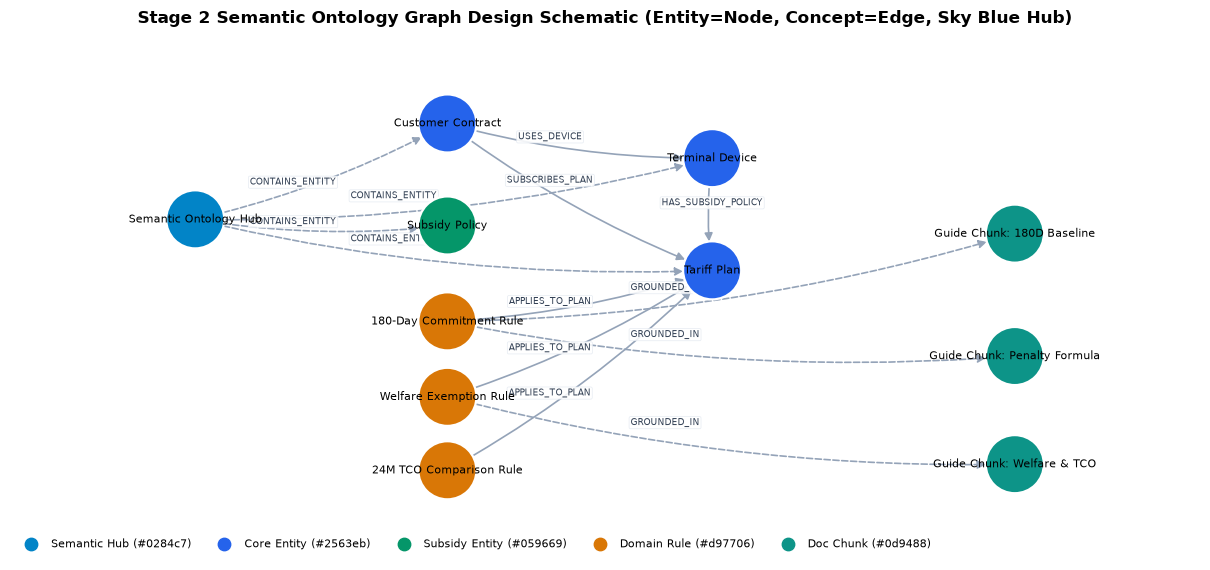

In [6]:
H.show(H.parse_guides_live_demo())
df_wiki, manifest = H.wiki_compilation_summary()
H.show(df_wiki)
res_s2 = server.execute_tool("mcp_stage2_wiki_and_semantic")
H.show_tool(res_s2, "anchored_chunks")
H.draw_semantic_design_graph()


### 4. [Phase 5 · Stage 3: Build Property Graph] `STARTER_ONTOLOGY_GRAPH` Metamodel, Executed GQL & Bound Variables, and Full Topology (`%%bqsql` + `H.run_gql`)


**`mcp_stage3_property_graph`** · engine `bigquery` · status `SUCCESS` · steps `promote_dw_nodes, synthesize_graph_ddl, verify_gql_templates` · jobs 2 (1,055.4 ms)

[BIGQUERY] 0 duplicate keys across node tables · 10 GQL paths (Device→Plan←Rule)

- `job_lFB2Nhg31TD4SF0s5yMYir8JzFwu`
- `job_02rgJVj9m-Lgph6CDZV1mWhZQTyO`

,node_table,row_count,duplicate_keys
0,tb_device_master,4,0
1,tb_plan_master,6,0
2,tb_subsidy_policy,5,0
3,tb_customer_contract,6,0
4,tb_doc_chunks,5,0
5,tb_domain_rules,4,0


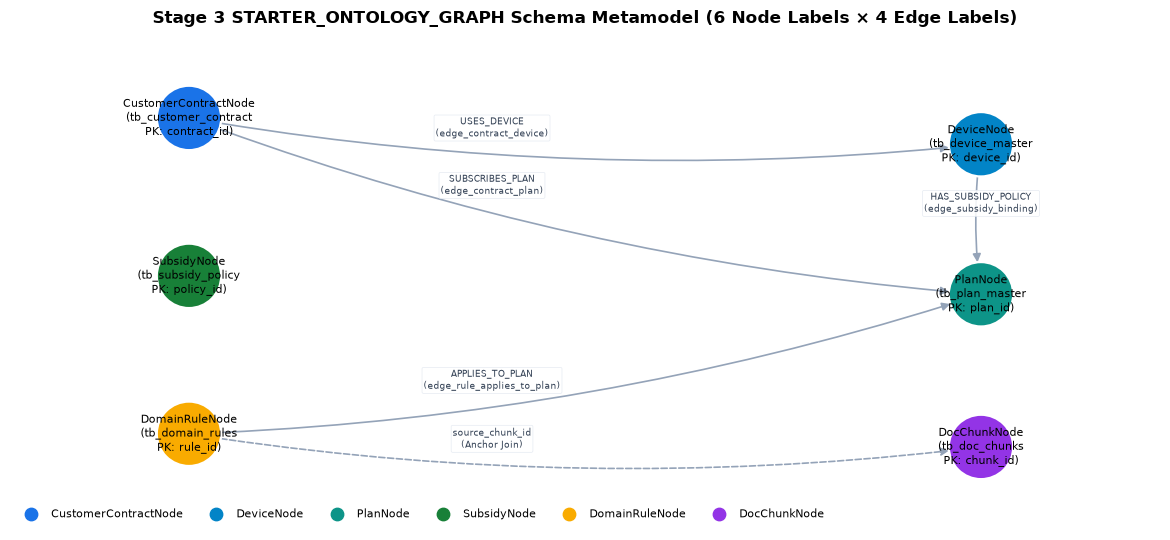

In [7]:
res_s3 = server.execute_tool("mcp_stage3_property_graph")
H.show_tool(res_s3, "node_tables")
H.draw_property_graph_metamodel()


In [8]:
%%bqsql df_paths
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (a)-[e]->(b)
RETURN TO_JSON(p) AS path


,path
0,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
1,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
2,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
3,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
4,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
5,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
6,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
7,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
8,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
9,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."


#### 3-Hop ISO GQL Execution (Customer Contract → Device/Plan ← Domain Rule + DocChunk)
- **BigQuery ISO GQL Execution**: status `SUCCESS` · job `job_vlWi3JubmAAC6kBvD7nDTaDHyuil` · `511 ms` · `2 rows`

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | Target BigQuery Property Graph |
| `c.customer_id` | `'CUST_DEMO_001'` | CustomerContractNode filter parameter |
| `ch.chunk_id` | `ap.source_chunk_id` | DocChunkNode SHA-256 anchor join key |

**2) Executed ISO GQL Statement**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode),
      (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode),
      (ch:DocChunkNode)
WHERE c.customer_id = 'CUST_DEMO_001' AND ch.chunk_id = ap.source_chunk_id
RETURN c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name,
       r.rule_id AS rule_id, ap.source_chunk_id AS chunk_id, ch.content_sha256 AS sha256_anchor
ORDER BY r.rule_id
```

,customer_id,device_name,plan_name,rule_id,chunk_id,sha256_anchor
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0
1,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8


**Extracted physical graph nodes: `19` · edges: `29`**

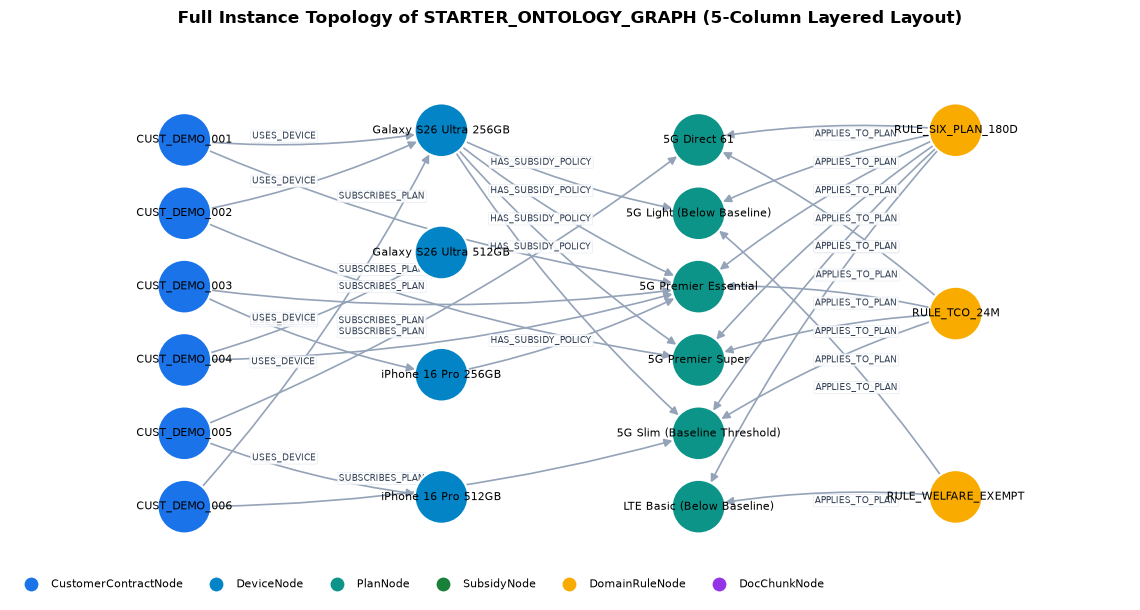

In [9]:
gql_cust_rules = """GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode),
      (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode),
      (ch:DocChunkNode)
WHERE c.customer_id = 'CUST_DEMO_001' AND ch.chunk_id = ap.source_chunk_id
RETURN c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name,
       r.rule_id AS rule_id, ap.source_chunk_id AS chunk_id, ch.content_sha256 AS sha256_anchor
ORDER BY r.rule_id"""
_ = H.run_gql(
    gql_cust_rules,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "Target BigQuery Property Graph"),
        "c.customer_id": ("'CUST_DEMO_001'", "CustomerContractNode filter parameter"),
        "ch.chunk_id": ("ap.source_chunk_id", "DocChunkNode SHA-256 anchor join key"),
    },
    title="3-Hop ISO GQL Execution (Customer Contract → Device/Plan ← Domain Rule + DocChunk)",
)
nodes, edges = H.paths_to_graph(H.pdf(df_paths)["path"])
H.md(f"**Extracted physical graph nodes: `{len(nodes)}` · edges: `{len(edges)}`**")
H.draw_graph(nodes, edges, "Full Instance Topology of STARTER_ONTOLOGY_GRAPH (5-Column Layered Layout)", legend=H.LABEL_COLORS)


### 5. [Phase 6–7 · Stage 4: Build Agent & Answer] 2-Pass Agent Blueprint, Live NL-to-GQL & Golden CQ Execution


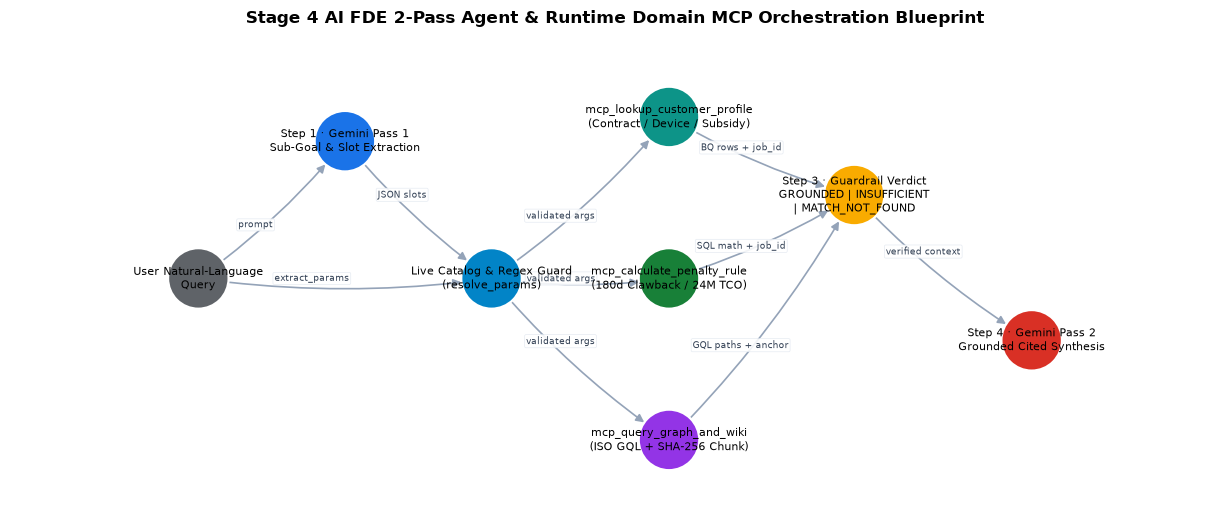

**Q.** Show each customer's device name, subscribed plan name, and monthly fee ordered by customer ID
- Gemini `gemini-3.8-flash`: Retrieves each customer's device name, plan name, and monthly fee by traversing the USES_DEVICE and SUBSCRIBES_PLAN relationships from CustomerContractNode. (tokens 1,722, 6,275 ms)

Attempt 1 · status `SUCCESS` · job `job_0pJo-7Cnr1toz1kSWVvXfdai2fiX` · 558 ms · 6 rows

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | Target BigQuery Property Graph |

**2) Executed ISO GQL Statement**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode) RETURN c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw ORDER BY customer_id LIMIT 50
```

,customer_id,device_name,plan_name,monthly_fee_krw
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CUST_DEMO_006,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


#### Golden CQ-03 · 120-Day Prorated Penalty Calculation
**Q.** If customer CUST_DEMO_001 downgrades to 5G Light (37,000 KRW) on day 120, what is the penalty and grounded anchor?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "5G Light"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 479 | `job__WEgZ0rrB-d-5DaPvbcwYN6wWuem` |
| 2 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 1,048 | `job_5VIHKDac32jB8cHLFJybAfKADDhB`, `job_B92en0SP239SWFoz_X110rAuuomo` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 559 | `job_tgTHXXA1dZ_lDgwBFkGARGQlCVA8` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "5G Light"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_001'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,961 tokens, LLM 38,936 ms / total 41.48 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### Conclusion
> If customer **CUST_DEMO_001** downgrades from **5G Premier Essential** (85,000 KRW) to **5G Light (Below Baseline)** (37,000 KRW) on day 120, the calculated penalty is **100,000 KRW**, grounded under anchor **`anchor_47971ec8e4d8`** (with graph anchor **`anchor_3003b683cea0`**).
>
> ---
>
> ### Grounded Data (BigQuery)
>
> - **Customer ID**: `CUST_DEMO_001` (Contract ID: `CONTRACT_DEMO_101`)
> - **Device**: Galaxy S26 Ultra 256GB (`DEV-S26U-256`)
> - **Factory Price**: 1,698,400 KRW
> - **Current Plan**: 5G Premier Essential (`PLAN-5G-85`), 85,000 KRW/month
> - **Target Plan**: 5G Light (Below Baseline) (`PLAN-5G-37`), 37,000 KRW/month
> - **Mandatory Retention Period**: 180 days
> - **Elapsed Days at Downgrade**: 120 days
> - **Initial Base Subsidy**: 450,000 KRW (Policy: `POL-2026-002`)
> - **Target Plan Base Subsidy**: 150,000 KRW
> - **Subsidy Difference**: 450,000 KRW - 150,000 KRW = 300,000 KRW
> - **Remaining Days**: 180 - 120 = 60 days
> - **Prorated Penalty Formula**:
>   $$\text{penalty} = \text{ROUND}\left((450,000 - 150,000) \times \frac{180 - 120}{180}\right) = \text{ROUND}\left(300,000 \times \frac{60}{180}\right) = 100,000\text{ KRW}$$
> - **Penalty Status**: `PRORATED_PENALTY`
> - **Total Penalty Amount**: 100,000 KRW
>
> ---
>
> ### Applied Rules & Source Chunks
>
> | Rule ID | Rule Name | Source Chunk ID | Anchor |
> | :--- | :--- | :--- | :--- |
> | **RULE_SIX_PLAN_180D** | 180-Day Baseline (45,000 KRW) Mandatory Retention & Prorated Penalty Rule | `DOC_CHUNK_003` / `DOC_CHUNK_002` | `anchor_47971ec8e4d8` / `anchor_3003b683cea0` |
> | **RULE_SUBSIDY_CAP** | Public Subsidy & Retail Additional Subsidy Cap (15%) Rule | `DOC_CHUNK_001` | `anchor_a52e1a72869f` |
> | **RULE_TCO_24M** | 24-Month Public Subsidy vs. 25% Selective Contract TCO Comparison Rule | `DOC_CHUNK_005` | `anchor_4fbaf9c5cba8` |
>
> ---
>
> ### Related Information
>
> 1. **Baseline Threshold**: The mandatory baseline monthly fee threshold is 45,000 KRW. Because 5G Light is 37,000 KRW, it falls below the baseline threshold within the 180-day retention window, triggering the clawback. If the downgrade occurs after day 180, the penalty is 0 KRW.
> 2. **Welfare Status Exemption Check**: Customer `CUST_DEMO_001` has a `welfare_status` of `NONE`. Under `RULE_WELFARE_EXEMPT` (`DOC_CHUNK_004`, `anchor_269d9c42e05c`), only subscribers designated as `SENIOR_EXEMPT` receive a 100% exemption (0 KRW penalty), or `MILITARY_PAUSE_ELIGIBLE` receive a pause on their commitment counter.
> 3. **24-Month TCO Benchmark**: The customer's 24-month TCO under Public Subsidy is 3,220,900 KRW versus 3,228,400 KRW under the 25% selective discount, yielding a 7,500 KRW savings recommendation for the public subsidy track.
>
> ---
>
> ### Execution Telemetry
>
> - **`mcp_lookup_customer_profile` BigQuery Job ID**: `job__WEgZ0rrB-d-5DaPvbcwYN6wWuem`
> - **`mcp_calculate_penalty_rule` BigQuery Job IDs**: `job_5VIHKDac32jB8cHLFJybAfKADDhB`, `job_B92en0SP239SWFoz_X110rAuuomo`
> - **`mcp_query_graph_and_wiki` BigQuery Job ID**: `job_tgTHXXA1dZ_lDgwBFkGARGQlCVA8`

#### Golden CQ-05 · Senior Welfare Exemption & Multi-Hop Graph Path
**Q.** If customer CUST_DEMO_003 (Senior Welfare Eligible) switches to a senior plan on day 88, is the penalty exempted and what is the graph path?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"customer_id": "CUST_DEMO_003", "elapsed_days": 88, "target_plan_mention": "senior plan"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 1,370 | `job_ceSyjIAwFlE2ihET21qKkXjKOIl5` |
| 2 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 1,075 | `job_0MVFV5z11msNeQTzWOXo5jno-7ru`, `job_n6vcDTmdx-67IJJOK7xmlwHqODKL` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 569 | `job_tFlIvYm2SlrWxdu2VNsK5zKGVIde` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"customer_id": "CUST_DEMO_003", "elapsed_days": 88, "target_plan_mention": "senior plan"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_003'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,912 tokens, LLM 46,093 ms / total 49.11 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### Conclusion
> Yes, the penalty is fully exempted (0 KRW). Customer CUST_DEMO_003 holds the status `SENIOR_EXEMPT`, which waives all prorated clawback penalties when transitioning to a senior/welfare plan, despite switching on day 88 within the mandatory 180-day retention window. 
>
> The ontology graph path traversed in BigQuery is:
> `(c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)`
>
> ---
>
> ### Grounded Data (BigQuery)
> - **Customer ID**: CUST_DEMO_003
> - **Contract ID**: CONTRACT_DEMO_103
> - **Customer Segment**: Senior_Welfare (Age Group: 65+)
> - **Welfare Status**: SENIOR_EXEMPT
> - **Contract Type**: PUBLIC_SUBSIDY (24-month commitment)
> - **Elapsed Days**: 88 days (Mandatory retention threshold: 180 days)
> - **Device**: DEV-IP16P-256 (iPhone 16 Pro 256GB), Factory Price: 1,700,000 KRW
> - **Current Plan**: PLAN-5G-85 (5G Premier Essential), Monthly Fee: 85,000 KRW
> - **Granted Subsidy**: Base subsidy: 400,000 KRW + Additional subsidy cap: 60,000 KRW = Total subsidy: 460,000 KRW
> - **Penalty Status**: EXEMPT_WELFARE
> - **Calculated Penalty**: 0 KRW
>
> ---
>
> ### Applied Rules & Source Chunks
> 1. **RULE_WELFARE_EXEMPT** (`DOC_CHUNK_004`, Anchor: `anchor_269d9c42e05c`)
>    - *Rule Name*: Senior/Welfare Plan Transition & Military Suspension Penalty Exemption Rule
>    - *Condition*: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`
>    - *Formula*: `penalty = 0 (SENIOR_EXEMPT)`
>    - *Application*: Overrides standard prorated subsidy clawbacks under the 180-day retention rule for eligible senior welfare transitions.
>
> 2. **RULE_SIX_PLAN_180D** (`DOC_CHUNK_002` / `DOC_CHUNK_003`, Anchor: `anchor_3003b683cea0` / `anchor_47971ec8e4d8`)
>    - *Rule Name*: 180-Day Baseline (45,000 KRW) Mandatory Retention & Prorated Penalty Rule
>    - *Condition*: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>    - *Formula*: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>
> 3. **RULE_SUBSIDY_CAP** (`DOC_CHUNK_001`, Anchor: `anchor_a52e1a72869f`)
>    - *Rule Name*: Public Subsidy & Retail Additional Subsidy Cap (15%) Rule
>    - *Formula*: `total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory_price_krw - total_subsidy`
>
> 4. **RULE_TCO_24M** (`DOC_CHUNK_005`, Anchor: `anchor_4fbaf9c5cba8`)
>    - *Rule Name*: 24-Month Public Subsidy vs. 25% Selective Contract TCO Comparison Rule
>    - *Calculations*:
>      - `public_subsidy_24m_tco_krw`: 3,280,000 KRW
>      - `selective_24m_tco_krw`: 3,230,000 KRW
>      - Recommendation: `SELECTIVE_25PCT` (Savings: 50,000 KRW)
>
> ---
>
> ### Related Information
> - **Standard Baseline Requirement**: General subscribers downgrading below the 45,000 KRW monthly baseline fee prior to 180 days incur a prorated penalty based on remaining days `(180 - elapsed_days) / 180`. This penalty is bypassed solely due to the `SENIOR_EXEMPT` status.
> - **Graph Verification**: The graph query traversed 3 hops across 4 matched nodes in `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`, linking CONTRACT_DEMO_103 to `RULE_SIX_PLAN_180D` and `RULE_TCO_24M`.
>
> ---
>
> ### Execution Telemetry
> - **BigQuery Job IDs**:
>   - `job_ceSyjIAwFlE2ihET21qKkXjKOIl5` (Customer Profile Lookup)
>   - `job_0MVFV5z11msNeQTzWOXo5jno-7ru` (Penalty Exemption Pre-check)
>   - `job_n6vcDTmdx-67IJJOK7xmlwHqODKL` (Penalty Rule & TCO Calculation)
>   - `job_tFlIvYm2SlrWxdu2VNsK5zKGVIde` (Ontology Graph Traversal)

In [10]:
H.draw_agent_architecture()
node_labels, edge_labels, _ = H.graph_metadata()
schema_str = H.schema_text(node_labels, edge_labels)
_ = H.nl2gql("Show each customer's device name, subscribed plan name, and monthly fee ordered by customer ID", schema_str)
H.show_agent(agent.execute_cycle('If customer CUST_DEMO_001 downgrades to 5G Light (37,000 KRW) on day 120, what is the penalty and grounded anchor?'),
             "Golden CQ-03 · 120-Day Prorated Penalty Calculation")
H.show_agent(agent.execute_cycle('If customer CUST_DEMO_003 (Senior Welfare Eligible) switches to a senior plan on day 88, is the penalty exempted and what is the graph path?'),
             "Golden CQ-05 · Senior Welfare Exemption & Multi-Hop Graph Path")


### 6. [Phase 8 · Stage 5: Verify & Release Gate] End-to-End Lineage Summary & Gate 1–5 Readiness Verdict


In [11]:
res_s5 = server.execute_tool("mcp_stage5_lineage_and_eval")
H.show_tool(res_s5)
H.show(H.gate_checklist_table())


**`mcp_stage5_lineage_and_eval`** · engine `bigquery` · status `SUCCESS` · steps `build_4tier_lineage, run_golden_cq_suite, diagnose_boundary_failures` · jobs 1 (564.3 ms)

12 lineage join rows (bigquery) · Latest validation report: {'evaluated_at': '2026-09-30T23:15:42+09:00', 'run_id': '20260930T231542-82b2d488', 'total_cqs': 5, 'passed': 5, 'accuracy_rate': 100.0, 'synthetic_basis': True, 'unconfirmed_cqs': 5, 'method': 'sql CQ: verification_sql(BigQuery) vs expected_math + live agent answer; citation CQ: agent answer must cite expected chunk and contain expected_facts (Vertex AI gemini-3.8-flash); every final answer is also scored by an LLM judge on a 100-point rubric (PASS verdict required) and checked for duplicates'}

- `job_IFDrkwG0Wr13oHC3VoHyxVMohYIg`

,gate,criterion,measured_value,verdict
0,Gate 1 (Stage 1: Prepare & Analyze),"10 BQ tables loaded, 0 PII violations, 5 CQ SQL matches","tables=10/10, CQs=5",PASS
1,Gate 2 (Stage 2: Parse & Integrate),5 SHA-256 chunks anchored & 3-Layer Wiki synced to GCS,"chunks=5, status=LIVE_GCP_SYNCED",PASS
2,Gate 3 (Stage 3: Build Property Graph),STARTER_ONTOLOGY_GRAPH DDL SUCCESS & 0 duplicate node keys,"ddl=SUCCESS, dup_keys=0",PASS
3,Gate 4 (Stage 4: Agent & MCP Runtime),8 MCP tools active & guardrail statuses verified,"8 MCP tools (5 Stage + 3 Runtime), 2-Pass Gemini Engine",PASS
4,Gate 5 (Stage 5: Lineage & Release Gate),Golden CQ 5/5 (100%) & Boundary 10x5 (50 trials) benchmark passed,"CQ=5/5 (100.0%), Boundary=96.0% (50 trials)",PASS


### Q&A
- **Q.** How do structured DW tables and unstructured policy documents connect to produce grounded agent answers?
  - **A.** Through the 8-phase engineering pipeline (Prepare → Analyze → Parse → Integrate → Build Graph → Build Agent → Answer → Verify), 6 CSVs and 2 Markdown guides are unified into 10 BigQuery tables (`starter_ontology_dw`), a 3-Layer LLM-Wiki, and `STARTER_ONTOLOGY_GRAPH` (25 nodes, 29 edges), queried by 8 MCP tools and the 2-Pass Gemini (`gemini-3.8-flash`) agent.

### Data Analysis Key Findings
- Verified 10 BigQuery tables (62 total rows across 4 master, 2 knowledge, and 4 edge tables) with 0 de-identification violations (`CUST_DEMO_001~006`).
- All 5 policy chunks (`DOC_CHUNK_001~005`) match their stored SHA-256 anchors in `tb_doc_chunks`, with 0 duplicate keys and verified multi-hop paths in `STARTER_ONTOLOGY_GRAPH`.
- Latest reports: Golden CQ 5/5 (`100.0%`, 2026-09-30) and `96.0%` average success across 50 boundary trials (2026-09-27). The Gate 1–5 verdict follows the measured table above.

### Insights or Next Steps
- Proceed to the `Stage 1 (Prepare & Analyze)` notebook to inspect the raw CSV/guide schema design, data profiling, and Golden CQ verification SQL in detail.

---
> **Next Navigation**: [🏠 0. Overview Home](./stage0_overview_walkthrough_en.ipynb) ｜ [➡️ Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) ｜ [🌐 Korean Version](../ko/stage0_overview_walkthrough_ko.ipynb) ｜ [📖 Methodology Doc](../../methodology/en/METHODOLOGY_EN.md)
